<a href="https://colab.research.google.com/github/d24it177sakshishah/RSAI/blob/main/RSAI_D24IT177_External_Practical_Exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset


In [19]:
import os
dataset_dir = "/root/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1"
for root, dirs, files in os.walk(dataset_dir):
    print(f"Root: {root}")
    print(f"Dirs: {dirs}")
    print(f"Files: {files}")
    print("-" * 40)

In [20]:
import os
dataset_dir = "/root/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1"
for root, dirs, files in os.walk(dataset_dir):
    print(f"Root: {root}")
    print(f"Dirs: {dirs}")
    print(f"Files: {files}")
    print("-" * 40)

In [21]:
import os
dataset_dir = "/root/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1"
for root, dirs, files in os.walk(dataset_dir):
    print(f"Root: {root}")
    print(f"Dirs: {dirs}")
    print(f"Files: {files}")
    print("-" * 40)

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Train set size: {len(train_dataset)}")
print(f"Test set size: {len(test_dataset)}")

Train set size: 60000
Test set size: 10000


In [23]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BaselineCNN().to(device)
print(model)

BaselineCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training baseline CNN (2 epochs)... ", end="")
model.train()
for epoch in range(2):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
print("done.")

# Evaluate Clean Test Accuracy
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

clean_accuracy = 100 * correct / total
print(f"Clean test accuracy : {clean_accuracy:.1f} %")

Training baseline CNN (2 epochs)... done.
Clean test accuracy : 98.6 %


In [25]:
def fgsm_attack(image, epsilon, data_grad):
    # Collect the sign of the gradients
    sign_data_grad = data_grad.sign()
    # Create the perturbed image by adjusting each pixel of the input image
    perturbed_image = image + epsilon * sign_data_grad
    # Adding clipping to maintain [0,1] range
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def pgd_attack(model, images, labels, epsilon, alpha=None, num_iter=10):
    if alpha is None:
        alpha = epsilon / 4
    # Start with a random perturbation within the epsilon ball
    perturbed_images = images.clone().detach() + torch.FloatTensor(*images.shape).uniform_(-epsilon, epsilon).to(device)
    perturbed_images = torch.clamp(perturbed_images, 0, 1) # keep in [0, 1]

    for i in range(num_iter):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()

        # Gradient ascent step
        adv_images = perturbed_images + alpha * perturbed_images.grad.sign()
        # Projection back into the epsilon ball
        eta = torch.clamp(adv_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + eta, min=0, max=1).detach()

    return perturbed_images

In [26]:
epsilons = [0.00, 0.05, 0.10, 0.20, 0.30]
fgsm_accuracies = []
pgd_accuracies = []

# Evaluate baseline model under FGSM and PGD attacks
for eps in epsilons:
    if eps == 0.0:
        fgsm_accuracies.append(clean_accuracy)
        pgd_accuracies.append(clean_accuracy)
        continue

    fgsm_correct = 0
    pgd_correct = 0
    total = 0

    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        # --- FGSM Attack ---
        images.requires_grad = True
        outputs = model(images)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()

        data_grad = images.grad.data
        perturbed_images_fgsm = fgsm_attack(images, eps, data_grad)

        # Re-classify perturbed images
        outputs_fgsm = model(perturbed_images_fgsm)
        _, pred_fgsm = torch.max(outputs_fgsm.data, 1)
        fgsm_correct += (pred_fgsm == labels).sum().item()

        # --- PGD Attack ---
        perturbed_images_pgd = pgd_attack(model, images, labels, eps, alpha=eps/4, num_iter=10)
        outputs_pgd = model(perturbed_images_pgd)
        _, pred_pgd = torch.max(outputs_pgd.data, 1)
        pgd_correct += (pred_pgd == labels).sum().item()

        total += labels.size(0)

    fgsm_acc = 100 * fgsm_correct / total
    pgd_acc = 100 * pgd_correct / total
    fgsm_accuracies.append(fgsm_acc)
    pgd_accuracies.append(pgd_acc)

print("\nEPSILON    FGSM_ACC    PGD_ACC")
print("-------------------------------")
for i, eps in enumerate(epsilons):
    print(f" {eps:.2f}       {fgsm_accuracies[i]:.1f} %      {pgd_accuracies[i]:.1f} %")
print("-------------------------------")


EPSILON    FGSM_ACC    PGD_ACC
-------------------------------
 0.00       98.6 %      98.6 %
 0.05       94.7 %      93.8 %
 0.10       83.8 %      76.7 %
 0.20       41.9 %      4.2 %
 0.30       6.0 %      0.0 %
-------------------------------


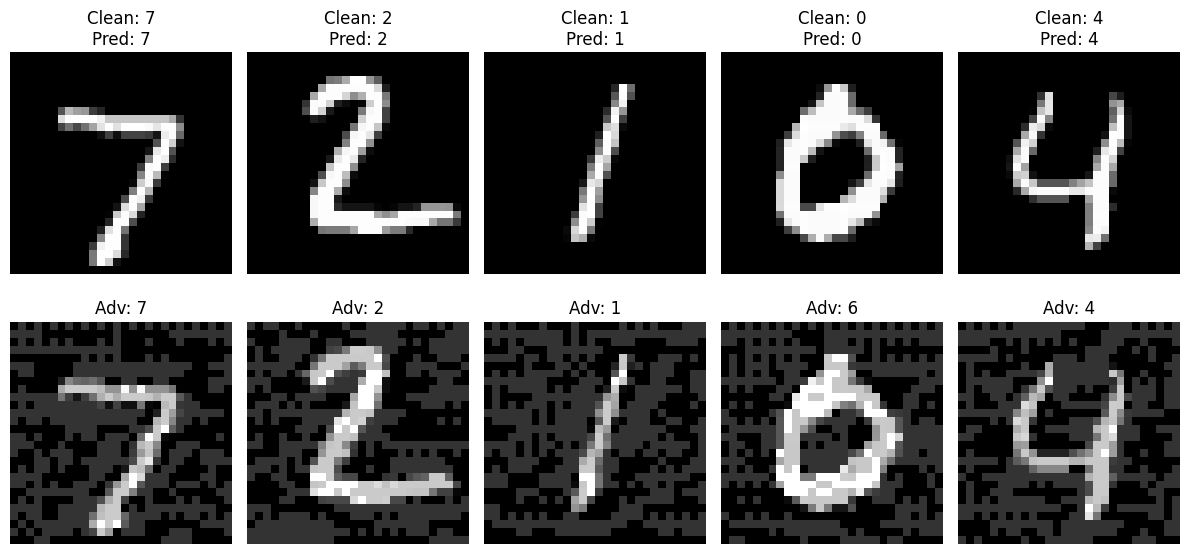

Mis-read digits saved : clean_vs_adversarial.png
Attack success (eps=0.20): FGSM 58.1 %, PGD 95.8 %


In [27]:
# Visualizing Clean vs Adversarial Digits (eps = 0.20)
model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)
images.requires_grad = True
outputs = model(images)
loss = criterion(outputs, labels)
model.zero_grad()
loss.backward()

perturbed_images = fgsm_attack(images, 0.20, images.grad.data)
outputs_adv = model(perturbed_images)
_, preds_clean = torch.max(outputs.data, 1)
_, preds_adv = torch.max(outputs_adv.data, 1)

# Prepare visualization plot of 5 digits
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i in range(5):
    # Clean Image
    axes[0, i].imshow(images[i].cpu().detach().numpy().squeeze(), cmap='gray')
    axes[0, i].set_title(f"Clean: {labels[i].item()}\nPred: {preds_clean[i].item()}")
    axes[0, i].axis('off')

    # Adversarial Image
    axes[1, i].imshow(perturbed_images[i].cpu().detach().numpy().squeeze(), cmap='gray')
    axes[1, i].set_title(f"Adv: {preds_adv[i].item()}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('clean_vs_adversarial.png')
plt.show()
print("Mis-read digits saved : clean_vs_adversarial.png")
print(f"Attack success (eps=0.20): FGSM {100 - fgsm_accuracies[3]:.1f} %, PGD {100 - pgd_accuracies[3]:.1f} %")

In [28]:
# Fine-tune using 50:50 mix of Clean and FGSM (eps = 0.20) images for 2 epochs
adv_model = BaselineCNN().to(device)
adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)

print("Training adversarially-hardened model... ", end="")
adv_model.train()
for epoch in range(2):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Generate FGSM perturbations for 50% of the batch
        batch_size = images.size(0)
        half_batch = batch_size // 2

        clean_images = images[:half_batch]
        adv_target_images = images[half_batch:]
        adv_labels = labels[half_batch:]

        adv_target_images.requires_grad = True
        # Temporarily use baseline or current model gradients for the perturbation creation
        outputs_for_grad = adv_model(adv_target_images)
        loss_for_grad = criterion(outputs_for_grad, adv_labels)
        adv_model.zero_grad()
        loss_for_grad.backward()

        perturbed_half = fgsm_attack(adv_target_images, 0.20, adv_target_images.grad.data).detach()

        # Combine back into a 50:50 mix
        mixed_images = torch.cat([clean_images, perturbed_half], dim=0)

        # Regular optimization step
        adv_optimizer.zero_grad()
        mixed_outputs = adv_model(mixed_images)
        mixed_loss = criterion(mixed_outputs, labels)
        mixed_loss.backward()
        adv_optimizer.step()
print("done.")

# Re-evaluate adversarially trained model at eps = 0.20
adv_model.eval()
adv_clean_correct = 0
adv_fgsm_correct = 0
adv_pgd_correct = 0
total = 0

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    total += labels.size(0)

    # Clean
    with torch.no_grad():
        outputs = adv_model(images)
        _, pred = torch.max(outputs.data, 1)
        adv_clean_correct += (pred == labels).sum().item()

    # FGSM
    images.requires_grad = True
    outputs = adv_model(images)
    loss = criterion(outputs, labels)
    adv_model.zero_grad()
    loss.backward()
    perturbed_fgsm = fgsm_attack(images, 0.20, images.grad.data)
    outputs_fgsm = adv_model(perturbed_fgsm)
    _, pred_fgsm = torch.max(outputs_fgsm.data, 1)
    adv_fgsm_correct += (pred_fgsm == labels).sum().item()

    # PGD
    perturbed_pgd = pgd_attack(adv_model, images, labels, 0.20, alpha=0.05, num_iter=10)
    outputs_pgd = adv_model(perturbed_pgd)
    _, pred_pgd = torch.max(outputs_pgd.data, 1)
    adv_pgd_correct += (pred_pgd == labels).sum().item()

adv_clean_acc = 100 * adv_clean_correct / total
adv_fgsm_acc = 100 * adv_fgsm_correct / total
adv_pgd_acc = 100 * adv_pgd_correct / total

print("\nMODEL              CLEAN    FGSM(0.20)   PGD(0.20)")
print("----------------------------------------------------")
print(f"Baseline           {clean_accuracy:.1f} %     {fgsm_accuracies[3]:.1f} %       {pgd_accuracies[3]:.1f} %")
print(f"Adversarially      {adv_clean_acc:.1f} %     {adv_fgsm_acc:.1f} %      {adv_pgd_acc:.1f} %")
print("trained")
print("----------------------------------------------------")
print(f"Clean accuracy change : {adv_clean_acc - clean_accuracy:+.1f} %")
print(f"FGSM robustness gain  : {adv_fgsm_acc - fgsm_accuracies[3]:+.1f} %    PGD gain : {adv_pgd_acc - pgd_accuracies[3]:+.1f} %")

Training adversarially-hardened model... done.

MODEL              CLEAN    FGSM(0.20)   PGD(0.20)
----------------------------------------------------
Baseline           98.6 %     41.9 %       4.2 %
Adversarially      98.4 %     91.0 %      10.8 %
trained
----------------------------------------------------
Clean accuracy change : -0.1 %
FGSM robustness gain  : +49.1 %    PGD gain : +6.6 %


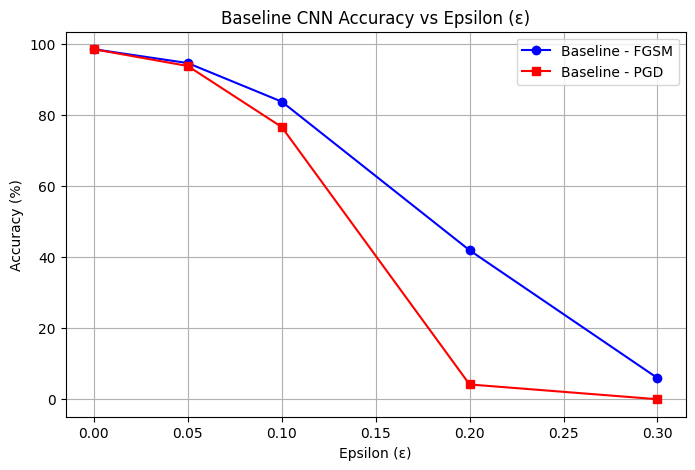

Plot saved : accuracy_vs_epsilon.png


In [29]:
# Plot Epsilon vs Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accuracies, marker='o', label='Baseline - FGSM', color='blue')
plt.plot(epsilons, pgd_accuracies, marker='s', label='Baseline - PGD', color='red')
plt.xlabel('Epsilon (ε)')
plt.ylabel('Accuracy (%)')
plt.title('Baseline CNN Accuracy vs Epsilon (ε)')
plt.legend()
plt.grid(True)
plt.savefig('accuracy_vs_epsilon.png')
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")